# Log-Loss (Cross-Entropy) for Statistical Classification
## Implementing and Training Logistic Regression from Scratch

**Workshop:** Statistical Classification and Logistic Regression — In-Class Activity

| | |
|---|---|
| **Author** | _Your name_ |
| **Peer (Team B)** | _Peer's name_ |
| **Repository** | _link to this repo_ |
| **Peer's repository** | _link to peer's repo_ |

---

### Abstract

This notebook implements the binary log-loss (cross-entropy) function from first principles and applies it to the *hours studied → pass/fail* use case. A logistic regression model is built in NumPy, and its weights are learned by minimising log-loss with batch gradient descent. Every component is verified independently: the loss against `sklearn.metrics.log_loss`, the analytical gradient against a numerical (finite-difference) estimate, and the learned weights against scikit-learn's unregularised `LogisticRegression`.

### Key results

| Metric | Value |
|---|---|
| Learned weights | $w_0 = -8.535$, $w_1 = 2.968$ |
| Training log-loss | **0.2321** (baseline 0.6918, a 66.5% reduction) |
| Decision boundary | 2.875 hours |
| Training accuracy | 89.47% (17 of 19) |
| Agreement with scikit-learn (`penalty=None`) | Weights match to two decimal places |

### Contents

1. [Data](#1.-Data)
2. [The Model: Linear Score and Sigmoid](#2.-The-Model:-Linear-Score-and-Sigmoid)
3. [Log-Loss (Cross-Entropy)](#3.-Log-Loss-(Cross-Entropy))
4. [Training with Gradient Descent](#4.-Training-with-Gradient-Descent)
5. [Results](#5.-Results)
6. [Evaluation in Context](#6.-Evaluation-in-Context)
7. [Learning-Rate Experiment](#7.-Learning-Rate-Experiment)
8. [Limitations](#8.-Limitations)
9. [Talking Points](#9.-Talking-Points)
10. [Peer Review Notes](#10.-Peer-Review-Notes)

### Approach

```
hours ──► z = w0 + w1·x ──► p = σ(z) ──► probability of passing
                                              │
                    actual outcome y ─────────┤
                                              ▼
                                 log-loss: how wrong is p?
                                              │
                                              ▼
                  gradient descent: adjust w0, w1 to reduce the loss
```

The model maps hours to a probability; log-loss scores that probability against the true outcome; gradient descent uses the score to improve the model. Log-loss therefore plays two roles: it is the **evaluation metric** and the **training objective**.

All code is written in NumPy so that each line maps directly to a formula. scikit-learn is used only for verification.

### Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss as sk_log_loss
from sklearn.linear_model import LogisticRegression


def verify(description, condition):
    # Print ✅ / ❌ for a verification check
    try:
        ok = bool(condition())
    except Exception as e:
        print(f"❌ {description} ({type(e).__name__}: {e})")
        return
    print(f"{'✅' if ok else '❌'} {description}")

---
## 1. Data

The dataset contains 19 students. `hours[i]` is the time student *i* studied; `passed[i]` is **1** if they passed and **0** if they failed.

The arrays are kept one-dimensional (shape `(19,)`). scikit-learn requires a 2-D *samples × features* matrix, but this implementation uses a single feature, so 1-D arrays are simpler and avoid shape errors.

Students: 19   Passed: 9   Pass rate: 0.474


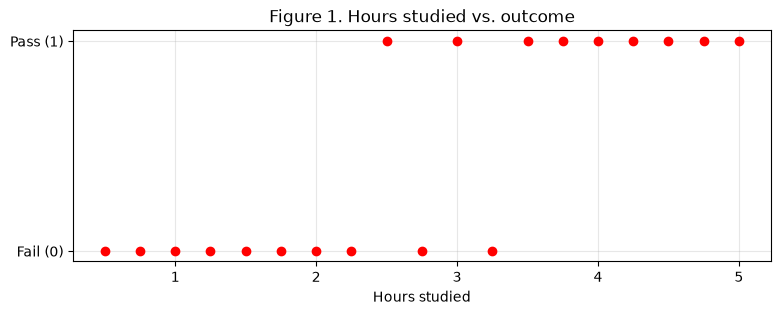

In [2]:
hours = np.array([0.5, 0.75, 1, 1.25, 1.5, 1.75, 2, 2.25, 2.5, 2.75,
                  3, 3.25, 3.5, 3.75, 4, 4.25, 4.5, 4.75, 5])
passed = np.array([0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1])

n_passed = int(np.sum(passed == 1))
pass_rate = n_passed / len(passed)

print(f"Students: {len(passed)}   Passed: {n_passed}   Pass rate: {pass_rate:.3f}")

plt.figure(figsize=(9, 3))
plt.scatter(hours, passed, color="red", zorder=3)
plt.yticks([0, 1], ["Fail (0)", "Pass (1)"])
plt.xlabel("Hours studied")
plt.title("Figure 1. Hours studied vs. outcome")
plt.grid(alpha=0.3)
plt.show()

In [3]:
verify("n_passed is 9", lambda: n_passed == 9)
verify("pass_rate is 9/19 ≈ 0.474", lambda: np.isclose(pass_rate, 9 / 19))

✅ n_passed is 9
✅ pass_rate is 9/19 ≈ 0.474


### Discussion

**Can any single cut-off classify every student correctly?**

No single cut-off can classify every student correctly because the classes overlap in the middle: the student at 2.5 hours passed, the one at 2.75 hours failed, the one at 3.0 hours passed, and the one at 3.25 hours failed. Real-world data is noisy, and unmeasured factors (prior knowledge, sleep, test anxiety) affect the outcome, so studying a set number of hours does not guarantee a deterministic result. Predicting a continuous probability captures this uncertainty: it tells us a student at around 2.8 hours is roughly a 50/50 toss-up, rather than forcing a brittle, overconfident yes/no rule.

---
## 2. The Model: Linear Score and Sigmoid

### 2.1 Linear score (log-odds)

$$z = w_0 + w_1 x$$

- $w_0$ (**intercept / bias**): the score of a student who studied 0 hours.
- $w_1$ (**weight**): how much each additional hour changes the score.
- $z$ is the **log-odds** of passing, $z = \log\frac{p}{1-p}$. It ranges over all real numbers, which is exactly the range of a straight line. $z = 0$ corresponds to 50/50 odds; $z = 2$ corresponds to odds of $e^2 \approx 7.4$ to 1 in favour of passing.

NumPy applies arithmetic element-wise (vectorisation), so the same function works for a single student and for the whole dataset.

In [4]:
def linear(x, w0, w1):
    # Log-odds of passing: z = w0 + w1 * x
    return w0 + w1 * x

In [5]:
verify("linear(2, 1, 3) == 7", lambda: linear(2, 1, 3) == 7)
verify("works on arrays", lambda: np.allclose(linear(np.array([0, 1, 2]), -1, 2), [-1, 1, 3]))

✅ linear(2, 1, 3) == 7
✅ works on arrays


### 2.2 Sigmoid

A probability must lie between 0 and 1, but $z$ is unbounded. The **sigmoid** maps $z$ back to a probability:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

- Large positive $z$: $e^{-z} \approx 0$, so $\sigma(z) \approx 1$
- Large negative $z$: $e^{-z}$ is very large, so $\sigma(z) \approx 0$
- $z = 0$: $\sigma(0) = \frac{1}{2}$

**Why the sigmoid?**
- A **straight line** (linear regression) predicts values such as −0.19 and 1.14 on this data, which are meaningless as probabilities.
- A **hard step** function gives no probability, and its derivative is zero almost everywhere, so gradient descent receives no learning signal.
- The **sigmoid** is smooth, bounded in (0, 1), and has the simple derivative $\sigma(z)\,(1 - \sigma(z))$, which is central to the gradient derivation in Section 4.

In [6]:
def sigmoid(z):
    # Map log-odds to a probability in (0, 1)
    return 1 / (1 + np.exp(-z))

✅ sigmoid(0) == 0.5
✅ sigmoid(10) is close to 1
✅ sigmoid(-10) is close to 0
✅ symmetry: sigmoid(-z) == 1 - sigmoid(z)
✅ works on arrays


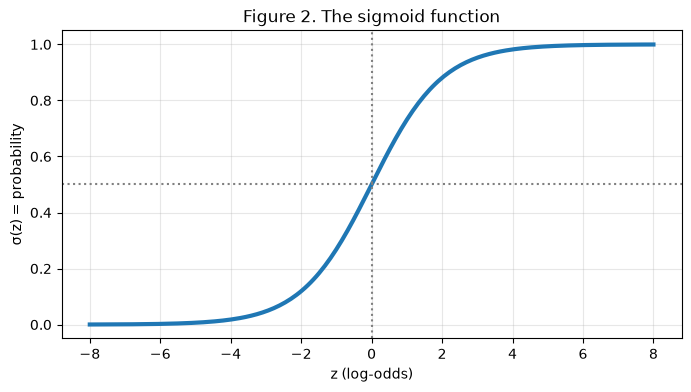

In [7]:
verify("sigmoid(0) == 0.5", lambda: sigmoid(0) == 0.5)
verify("sigmoid(10) is close to 1", lambda: 0.9999 < sigmoid(10) < 1)
verify("sigmoid(-10) is close to 0", lambda: 0 < sigmoid(-10) < 0.0001)
verify("symmetry: sigmoid(-z) == 1 - sigmoid(z)", lambda: np.isclose(sigmoid(-1.7), 1 - sigmoid(1.7)))
verify("works on arrays", lambda: sigmoid(np.zeros(5)).shape == (5,))

z = np.linspace(-8, 8, 200)
plt.figure(figsize=(8, 4))
plt.plot(z, sigmoid(z), lw=3)
plt.axhline(0.5, color="grey", linestyle=":")
plt.axvline(0, color="grey", linestyle=":")
plt.xlabel("z (log-odds)")
plt.ylabel("σ(z) = probability")
plt.title("Figure 2. The sigmoid function")
plt.grid(alpha=0.3)
plt.show()

### Discussion

**What would a negative $w_1$ mean?**

A negative $w_1$ means each additional hour of studying decreases the log-odds $z$, and therefore decreases the probability of passing. The S-curve would flip horizontally, starting high near 0 hours and dropping toward 0 as hours increase.

**Where is the decision boundary?**

The sigmoid outputs $p = 0.5$ precisely when the log-odds $z = 0$. Setting the linear equation to zero gives:

$$w_0 + w_1 x = 0 \implies x = -\frac{w_0}{w_1}$$

---
## 3. Log-Loss (Cross-Entropy)

The model outputs probabilities; log-loss measures how good those probabilities are. In one sentence: *take the probability the model assigned to what actually happened, and compute minus its log.*

### 3.1 Per-sample loss (piecewise form)

$$
\text{loss} =
\begin{cases}
-\log(p), & y = 1 \text{ (passed)} \\
-\log(1 - p), & y = 0 \text{ (failed)}
\end{cases}
$$

where $p$ is the predicted probability of passing.

- The logarithm of a number in (0, 1) is negative; the minus sign turns it into a positive cost.
- $-\log(1) = 0$: confident and correct gives no penalty.
- As the probability assigned to the truth approaches 0, $-\log$ grows without bound: **confident and wrong gives a very large penalty**.

| Probability assigned to the true outcome | Loss |
|---|---|
| 0.99 | 0.010 |
| 0.90 | 0.105 |
| 0.50 | 0.693 |
| 0.10 | 2.303 |
| 0.01 | 4.605 |

In [8]:
def single_loss(y, p):
    # Log-loss for one student (piecewise form)
    if y == 1:
        return -np.log(p)
    else:
        return -np.log(1 - p)

In [9]:
verify("passed, p = 0.9  -> 0.105 (confident and correct)", lambda: np.isclose(single_loss(1, 0.9), 0.10536, atol=1e-4))
verify("failed, p = 0.9  -> 2.303 (confident and wrong)", lambda: np.isclose(single_loss(0, 0.9), 2.30259, atol=1e-4))
verify("passed, p = 0.5  -> 0.693 (uncertain)", lambda: np.isclose(single_loss(1, 0.5), 0.69315, atol=1e-4))
verify("failed, p = 0.05 -> 0.051 (confident and correct)", lambda: np.isclose(single_loss(0, 0.05), 0.05129, atol=1e-4))

✅ passed, p = 0.9  -> 0.105 (confident and correct)
✅ failed, p = 0.9  -> 2.303 (confident and wrong)
✅ passed, p = 0.5  -> 0.693 (uncertain)
✅ failed, p = 0.05 -> 0.051 (confident and correct)


### 3.2 Vectorised log-loss (compact form)

A single expression handles both cases, using $y$ as a switch:

$$\text{loss} = -\left[\,y\log(p) + (1-y)\log(1-p)\,\right]$$

Substituting $y = 1$ removes the second term, leaving $-\log(p)$; substituting $y = 0$ removes the first, leaving $-\log(1-p)$. Because there is no branching, NumPy can evaluate it for all students at once. The dataset loss is the mean over $N$ students:

$$L = -\frac{1}{N}\sum_{i=1}^{N}\left[\,y_i\log(p_i) + (1-y_i)\log(1-p_i)\,\right]$$

**Numerical safety.** If $p$ is exactly 0 or 1, $\log(0) = -\infty$ and the result becomes `inf` or `nan`. Probabilities are therefore clipped to $[\varepsilon,\, 1-\varepsilon]$ with $\varepsilon = 10^{-15}$, which caps the worst single-sample loss at about 34.5.

In [10]:
def log_loss(y_true, y_prob, eps=1e-15):
    # Average binary cross-entropy
    y_prob = np.clip(y_prob, eps, 1 - eps)
    losses = -(y_true * np.log(y_prob) + (1 - y_true) * np.log(1 - y_prob))
    return np.mean(losses)

In [11]:
p_test = np.array([0.1, 0.4, 0.35, 0.8, 0.9])
y_test = np.array([0, 0, 1, 1, 1])

verify("every p = 0.5 gives ln 2 ≈ 0.6931 (uninformed model)",
       lambda: np.isclose(log_loss(passed, np.full(19, 0.5)), np.log(2)))
verify("agrees with single_loss averaged in a loop",
       lambda: np.isclose(log_loss(y_test, p_test), np.mean([single_loss(y, p) for y, p in zip(y_test, p_test)])))
verify("matches sklearn.metrics.log_loss",
       lambda: np.isclose(log_loss(y_test, p_test), sk_log_loss(y_test, p_test)))
verify("clipping: p = 0 and p = 1 give a finite loss",
       lambda: np.isfinite(log_loss(np.array([1, 0]), np.array([0.0, 1.0]))))

✅ every p = 0.5 gives ln 2 ≈ 0.6931 (uninformed model)
✅ agrees with single_loss averaged in a loop
✅ matches sklearn.metrics.log_loss
✅ clipping: p = 0 and p = 1 give a finite loss


Every later result depends on this function, so it is verified against a trusted implementation before anything is built on top of it.

### Discussion

**Why does log-loss punish a confident wrong answer far more than an uncertain one?**

Log-loss evaluates $-\log(\text{probability assigned to the true outcome})$. If a student fails ($y=0$) and the model predicted $p=0.55$ of passing, it assigned $0.45$ to the truth, giving a modest loss of $-\log(0.45) \approx 0.80$, close to the uncertain loss of $0.693$. If the model was 99% sure the student would pass, it assigned only $0.01$ to the true outcome, and the loss rises steeply to $-\log(0.01) = 4.605$.

**Why not use accuracy to judge the model?**

Accuracy is a step metric based on a hard threshold of $0.5$. It treats a barely-correct prediction of $0.51$ the same as a confident prediction of $0.99$ for a student who passed, so it ignores calibration. Because accuracy changes in discrete jumps, its gradient is zero almost everywhere, which makes it unusable for gradient descent.

**What would happen without `np.clip`?**

If the model outputs exactly 0.0 or 1.0 (through floating-point underflow or overflow at extreme $z$), `np.log(0)` evaluates to $-\infty$. Multiplying $0 \times (-\infty)$ in the compact formula produces `nan`, which corrupts the mean loss and breaks training.

---
## 4. Training with Gradient Descent

The goal is to find the weights $w_0, w_1$ that minimise the log-loss. Unlike linear regression, logistic regression has **no closed-form solution**: the weights sit inside the sigmoid, so the optimality equations cannot be rearranged into $w = \ldots$. The minimum is found iteratively with gradient descent:

$$w \leftarrow w - \eta\,\frac{\partial L}{\partial w}$$

where $\eta$ is the learning rate.

### 4.1 Gradient derivation

Applying the chain rule for one sample (loss ← $p$ ← $z$ ← $w_1$):

$$
\frac{\partial\,\text{loss}}{\partial w_1}
= \underbrace{\frac{p - y}{p(1-p)}}_{\partial\,\text{loss}/\partial p}
\;\cdot\; \underbrace{p(1-p)}_{\partial p/\partial z}
\;\cdot\; \underbrace{x}_{\partial z/\partial w_1}
= (p - y)\,x
$$

The $p(1-p)$ terms cancel. For $w_0$ the final factor is 1. Averaged over the dataset:

$$\frac{\partial L}{\partial w_0} = \text{mean}(p - y) \qquad\qquad \frac{\partial L}{\partial w_1} = \text{mean}\big((p - y)\cdot x\big)$$

$(p - y)$ is the prediction error for each student, so students the model gets most wrong have the largest influence on each update.

### Why log-loss rather than mean squared error?

With MSE and a sigmoid, the gradient with respect to $z$ is $2(p - y)\cdot p(1-p)$; the $p(1-p)$ factor does not cancel and becomes very small when the model is confidently wrong:

| Loss | Gradient w.r.t. $z$ at $p = 0.01$, $y = 1$ |
|---|---|
| MSE | ≈ −0.020 |
| Log-loss | −0.99 (about 50× stronger) |

Log-loss is also **convex** in the weights for this model, so gradient descent cannot become trapped in a poor local minimum.

In [12]:
def gradients(x, y, w0, w1):
    # Gradients of the average log-loss with respect to w0 and w1
    p = sigmoid(linear(x, w0, w1))
    error = p - y
    grad_w0 = np.mean(error)
    grad_w1 = np.mean(error * x)
    return grad_w0, grad_w1

**Verification by numerical gradients.** A derivative measures how much the output changes when the input is nudged slightly. The analytical gradient is compared with a central-difference estimate,

$$\frac{\partial L}{\partial w_1} \approx \frac{L(w_1 + h) - L(w_1 - h)}{2h},$$

at several points in weight space.

In [13]:
def numerical_gradients(x, y, w0, w1, h=1e-6):
    # Central-difference estimate of the gradient
    L = lambda a, b: log_loss(y, sigmoid(linear(x, a, b)))
    d_w0 = (L(w0 + h, w1) - L(w0 - h, w1)) / (2 * h)
    d_w1 = (L(w0, w1 + h) - L(w0, w1 - h)) / (2 * h)
    return d_w0, d_w1


for a, b in [(0.0, 0.0), (-4.0, 1.5), (2.0, -1.0), (-8.5, 3.0), (1.0, 0.5)]:
    verify(f"analytical gradient matches numerical estimate at w0={a:.2f}, w1={b:.2f}",
           lambda: np.allclose(gradients(hours, passed, a, b), numerical_gradients(hours, passed, a, b), atol=1e-6))

✅ analytical gradient matches numerical estimate at w0=0.00, w1=0.00
✅ analytical gradient matches numerical estimate at w0=-4.00, w1=1.50
✅ analytical gradient matches numerical estimate at w0=2.00, w1=-1.00
✅ analytical gradient matches numerical estimate at w0=-8.50, w1=3.00
✅ analytical gradient matches numerical estimate at w0=1.00, w1=0.50


### 4.2 Training loop

Training starts from $w_0 = w_1 = 0$, which assigns $p = 0.5$ to every student (an uninformed starting point). Because the loss is convex, any starting point reaches the same minimum. Each iteration computes the probabilities, records the loss, and steps against the gradient.

In [14]:
def train(x, y, learning_rate=0.5, n_iterations=5000):
    # Batch gradient descent on the average log-loss
    w0, w1 = 0.0, 0.0
    history = []
    for _ in range(n_iterations):
        p = sigmoid(linear(x, w0, w1))
        history.append(log_loss(y, p))
        grad_w0, grad_w1 = gradients(x, y, w0, w1)
        w0 -= learning_rate * grad_w0
        w1 -= learning_rate * grad_w1
    return w0, w1, history


w0, w1, loss_history = train(hours, passed)
print(f"w0 = {w0:.4f}, w1 = {w1:.4f}")
print(f"Log-loss: {loss_history[0]:.4f} (start) -> {loss_history[-1]:.4f} (end)")

w0 = -8.5348, w1 = 2.9684
Log-loss: 0.6931 (start) -> 0.2321 (end)


✅ starts at ln 2 ≈ 0.6931
✅ loss never increases
✅ final loss ≈ 0.2321


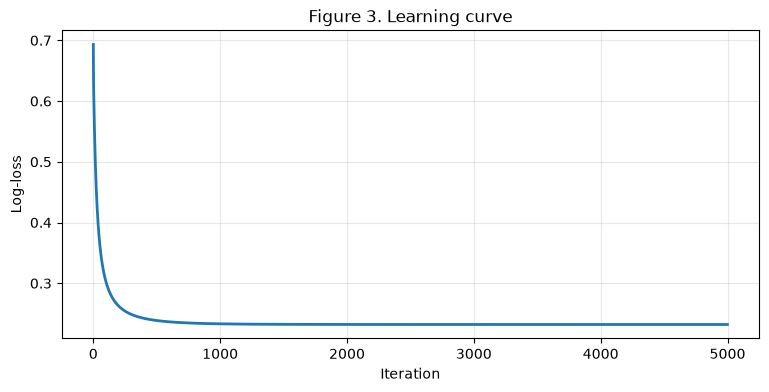

In [15]:
verify("starts at ln 2 ≈ 0.6931", lambda: np.isclose(loss_history[0], np.log(2)))
verify("loss never increases", lambda: np.all(np.diff(loss_history) <= 1e-12))
verify("final loss ≈ 0.2321", lambda: np.isclose(loss_history[-1], 0.2321, atol=1e-3))

plt.figure(figsize=(9, 4))
plt.plot(loss_history, lw=2)
plt.xlabel("Iteration")
plt.ylabel("Log-loss")
plt.title("Figure 3. Learning curve")
plt.grid(alpha=0.3)
plt.show()

### Discussion

**Why is the learning curve steep at first and flat later?**

The curve drops sharply during the first few hundred iterations and gradually flattens toward an asymptote of about $0.2321$. At the start ($w_0 = w_1 = 0$), every student is predicted at $p = 0.5$, so the errors $(p - y)$ are large across the board, producing steep gradients and large parameter updates. As the weights approach their optimal values, most predictions move close to the true $y$, the gradients shrink, and the updates become very small.

**Why is the gradient simply $(p - y)\,x$, and why is that a sensible way to learn?**

Mathematically, when the chain rule is applied, the derivative of the sigmoid, $p(1-p)$, cancels the $p(1-p)$ denominator from the derivative of log-loss. Intuitively, this is ideal because the update size is directly proportional to the prediction error $(p - y)$, scaled by the feature value $x$: small mistakes cause small adjustments, while confident mistakes trigger strong corrections without suffering from vanishing gradients.

---
## 5. Results

### 5.1 Decision boundary and accuracy

In [16]:
boundary = -w0 / w1
probabilities = sigmoid(linear(hours, w0, w1))
predictions = (probabilities >= 0.5).astype(int)
accuracy = np.mean(predictions == passed)

print(f"Decision boundary: {boundary:.3f} hours")
print(f"Training accuracy: {accuracy:.2%} ({np.sum(predictions == passed)} of {len(passed)})")

Decision boundary: 2.875 hours
Training accuracy: 89.47% (17 of 19)


✅ boundary ≈ 2.875 hours
✅ predictions are 0/1 for all 19 students
✅ accuracy = 17/19 ≈ 89.47%


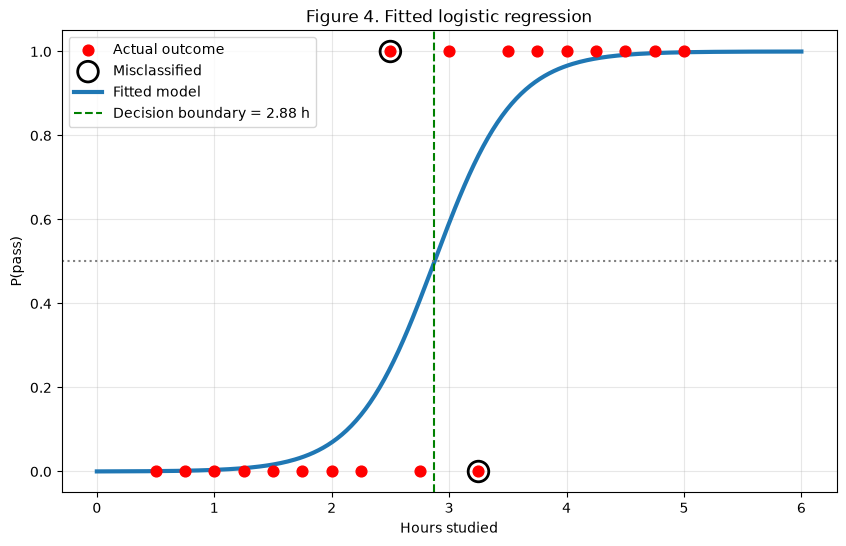

In [17]:
verify("boundary ≈ 2.875 hours", lambda: np.isclose(boundary, 2.875, atol=0.01))
verify("predictions are 0/1 for all 19 students",
       lambda: predictions.shape == (19,) and set(np.unique(predictions)) <= {0, 1})
verify("accuracy = 17/19 ≈ 89.47%", lambda: np.isclose(accuracy, 17 / 19))

x_grid = np.linspace(0, 6, 300)
wrong = predictions != passed

plt.figure(figsize=(10, 6))
plt.scatter(hours, passed, color="red", zorder=3, s=60, label="Actual outcome")
plt.scatter(hours[wrong], passed[wrong], facecolors="none", edgecolors="black", s=220,
            linewidths=2, zorder=4, label="Misclassified")
plt.plot(x_grid, sigmoid(linear(x_grid, w0, w1)), lw=3, label="Fitted model")
plt.axvline(boundary, color="green", linestyle="--", label=f"Decision boundary = {boundary:.2f} h")
plt.axhline(0.5, color="grey", linestyle=":")
plt.xlabel("Hours studied")
plt.ylabel("P(pass)")
plt.title("Figure 4. Fitted logistic regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Table 1.** Per-student predictions and loss contribution.

In [18]:
print(f"{'Hours':>5} | {'y':>1} | {'P(pass)':>7} | {'Loss':>5}")
print("-" * 32)
for h, y, p in zip(hours, passed, probabilities):
    flag = "  misclassified" if (p >= 0.5) != y else ""
    print(f"{h:>5} | {y:>1} | {p:7.3f} | {single_loss(y, p):5.3f}{flag}")

Hours | y | P(pass) |  Loss
--------------------------------
  0.5 | 0 |   0.001 | 0.001
 0.75 | 0 |   0.002 | 0.002
  1.0 | 0 |   0.004 | 0.004
 1.25 | 0 |   0.008 | 0.008
  1.5 | 0 |   0.017 | 0.017
 1.75 | 0 |   0.034 | 0.035
  2.0 | 0 |   0.069 | 0.072
 2.25 | 0 |   0.135 | 0.145
  2.5 | 1 |   0.247 | 1.398  misclassified
 2.75 | 0 |   0.408 | 0.525
  3.0 | 1 |   0.592 | 0.525
 3.25 | 0 |   0.753 | 1.397  misclassified
  3.5 | 1 |   0.865 | 0.145
 3.75 | 1 |   0.931 | 0.072
  4.0 | 1 |   0.966 | 0.035
 4.25 | 1 |   0.983 | 0.017
  4.5 | 1 |   0.992 | 0.008
 4.75 | 1 |   0.996 | 0.004
  5.0 | 1 |   0.998 | 0.002


### 5.2 Predictions for new students

Each label is derived from the predicted probability rather than written by hand, so the reported class cannot contradict the model's output.

In [19]:
def predict(h):
    # Return (probability of passing, "Pass" or "Fail")
    prob = float(sigmoid(linear(h, w0, w1)))
    label = "Pass" if prob >= 0.5 else "Fail"
    return prob, label


verify("2.6 h -> Fail", lambda: predict(2.6)[1] == "Fail")
verify("2.9 h -> Pass", lambda: predict(2.9)[1] == "Pass")
verify("probability lies in (0, 1)", lambda: 0 < predict(4)[0] < 1)

for h in [1.0, 2.6, 2.9, 4.5]:
    p, label = predict(h)
    print(f"{h} h -> P(pass) = {p:.3f} -> {label}")

✅ 2.6 h -> Fail
✅ 2.9 h -> Pass
✅ probability lies in (0, 1)
1.0 h -> P(pass) = 0.004 -> Fail
2.6 h -> P(pass) = 0.306 -> Fail
2.9 h -> P(pass) = 0.518 -> Pass
4.5 h -> P(pass) = 0.992 -> Pass


### Discussion

**Which students are misclassified, and why can no threshold fix both?**

With the decision boundary at $2.875$ hours, the two misclassified students are the one who studied $2.5$ hours and passed (predicted fail) and the one who studied $3.25$ hours and failed (predicted pass). No threshold can fix both: moving the boundary below $2.5$ to catch the first student would misclassify the failures at $2.75$ and $3.25$, while moving it above $3.25$ to fix the second would misclassify the passes at $2.5$ and $3.0$.

**Accuracy stopped at 89.47%, yet the log-loss kept falling. What was still improving?**

Once the boundary settles near $2.875$ hours, the 0/1 classifications stop changing, so accuracy stays at $17/19$. Log-loss continues to fall because gradient descent keeps steepening the sigmoid, pushing probabilities for clear passes (such as 4.5 h) closer to 1 and clear failures (such as 1.0 h) closer to 0, which improves the model's confidence on the students it already classifies correctly.

---
## 6. Evaluation in Context

A loss value is only meaningful relative to a reference. Two comparisons are made: a no-information baseline, and scikit-learn's implementation.

### 6.1 Baseline

The baseline ignores hours entirely and predicts the overall pass rate for every student.

In [20]:
baseline_loss = log_loss(passed, np.full(len(passed), pass_rate))

verify("baseline log-loss ≈ 0.6918", lambda: np.isclose(baseline_loss, 0.6918, atol=1e-3))
print(f"Baseline: {baseline_loss:.4f}   Model: {loss_history[-1]:.4f}   "
      f"Reduction: {1 - loss_history[-1] / baseline_loss:.1%}")

✅ baseline log-loss ≈ 0.6918
Baseline: 0.6918   Model: 0.2321   Reduction: 66.5%


### 6.2 Comparison with scikit-learn

- `LogisticRegression(penalty=None)` minimises plain log-loss, as this implementation does, so the weights should match.
- `LogisticRegression()` (the default, used in the workshop notebook) adds **L2 regularisation**, which penalises large weights. This produces a flatter curve and a higher training loss.

In [21]:
X = hours.reshape(-1, 1)
sk_plain = LogisticRegression(penalty=None, max_iter=1000).fit(X, passed)
sk_default = LogisticRegression().fit(X, passed)

print(f"{'Model':<28} | {'w0':>7} | {'w1':>6} | {'Log-loss':>8}")
print("-" * 58)
print(f"{'This implementation':<28} | {w0:7.3f} | {w1:6.3f} | {loss_history[-1]:8.4f}")
for name, m in [("sklearn, penalty=None", sk_plain), ("sklearn default (L2, C=1)", sk_default)]:
    print(f"{name:<28} | {m.intercept_[0]:7.3f} | {m.coef_[0][0]:6.3f} | "
          f"{sk_log_loss(passed, m.predict_proba(X)[:, 1]):8.4f}")

verify("weights match sklearn's unregularised model",
       lambda: np.allclose([w0, w1], [sk_plain.intercept_[0], sk_plain.coef_[0][0]], atol=0.05))

Model                        |      w0 |     w1 | Log-loss
----------------------------------------------------------
This implementation          |  -8.535 |  2.968 |   0.2321
sklearn, penalty=None        |  -8.540 |  2.970 |   0.2321
sklearn default (L2, C=1)    |  -4.517 |  1.568 |   0.2754
✅ weights match sklearn's unregularised model


/Users/namy/.cache/uv/archive-v0/fzNNgXtYrAgl6mju/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


### Discussion

**What does the baseline tell us about whether hours studied is useful?**

Always predicting the average pass rate ($9/19 \approx 0.474$) gives a baseline log-loss of $0.6918$, nearly identical to the coin-flip loss of $\ln 2 \approx 0.6931$. Including hours reduces the log-loss to $0.2321$, a 66.5% reduction, which shows that study time carries strong predictive signal.

**Is this model better than the workshop's scikit-learn model because its loss is lower (0.232 vs. 0.275)?**

Not necessarily on unseen data. Our gradient descent matches `LogisticRegression(penalty=None)` ($w_0 \approx -8.53$, $w_1 \approx 2.97$), which purely minimises training loss. scikit-learn's default model applies L2 regularisation, penalising large weights ($w_0 \approx -4.52$, $w_1 \approx 1.57$) to keep the probability curve smoother. Although the regularised model has a higher training loss ($0.2754$), it protects against overfitting the small sample of 19 students and prevents the model from becoming overconfident on new data.

---
## 7. Learning-Rate Experiment

The same model is trained with four learning rates for 2,000 iterations each.

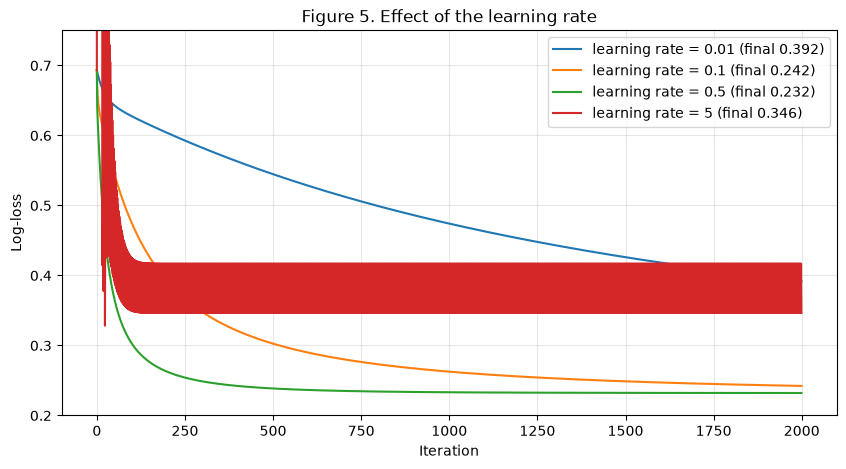

In [22]:
plt.figure(figsize=(10, 5))
for lr in [0.01, 0.1, 0.5, 5]:
    _, _, hist = train(hours, passed, learning_rate=lr, n_iterations=2000)
    plt.plot(hist, label=f"learning rate = {lr} (final {hist[-1]:.3f})")
plt.ylim(0.2, 0.75)
plt.xlabel("Iteration")
plt.ylabel("Log-loss")
plt.title("Figure 5. Effect of the learning rate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Discussion

**What goes wrong with a learning rate of 0.01, and of 5?**

- **0.01 (too small):** gradient descent takes tiny steps, so convergence is slow; after 2,000 iterations the loss is still above $0.35$ and has not reached the minimum.
- **5 (too large):** each step overshoots the bottom of the loss valley, bouncing back and forth across the walls of the bowl. The loss oscillates throughout all 2,000 iterations and never settles, ending at about $0.35$, well above the minimum of $0.232$.

**How would you choose a learning rate for a new problem?**

Run a logarithmic grid search over several orders of magnitude (for example 0.001, 0.01, 0.1, 0.5, 1.0) for a few hundred iterations and plot the loss curves. Choose the largest learning rate whose loss decreases smoothly and rapidly without oscillating or diverging.

---
## 8. Limitations

- **Training vs. test data.** The model was trained and evaluated on the same 19 students. With such a small dataset and no held-out test set (or cross-validation), the reported log-loss of $0.2321$ and accuracy of $89.47\%$ are optimistic training metrics that may not generalise to new students.
- **Only one feature.** Passing an exam depends on more than hours studied (for example prior GPA, attendance, sleep, practice-test scores). Relying solely on hours leaves unexplained variance, which is why students between $2.5$ and $3.25$ hours have overlapping outcomes.
- **The 0.5 threshold.** A $0.5$ cut-off assumes false positives and false negatives have equal cost. If the model were used as an early-warning system to assign tutoring to at-risk students, missing a student who goes on to fail is much worse than giving extra help to one who would have passed. In that scenario, requiring a higher probability before labelling a student "Pass" (for example $0.75$ or $0.80$) would be more appropriate.

---
## 9. Talking Points

### Talking Point 1: Why log-loss instead of accuracy or MSE

**Claim.** Log-loss is better suited than accuracy or mean squared error because it heavily penalises confident mistakes and provides a strong, non-vanishing gradient for optimisation.

**Evidence.** In Section 3, a confident wrong prediction (probability $0.01$ assigned to the true outcome) yields a loss of $4.605$, whereas an uncertain prediction ($0.50$) yields $0.693$. In Section 4, combining log-loss with the sigmoid cancels the $p(1-p)$ term, so the gradient with respect to $z$ at $p = 0.01$, $y = 1$ is $-0.99$, roughly 50× stronger than MSE's $-0.020$.

**Why it matters.** Trained with MSE, the model would barely learn from its worst, most confident errors, because the flat tails of the sigmoid make the gradient vanish. Log-loss keeps the optimisation problem convex and responsive.

### Talking Point 2: Verification with numerical gradients and baselines

**Claim.** Custom machine-learning code should be verified against brute-force finite differences, a trusted library, and a naive baseline before its outputs are trusted.

**Evidence.** In Sections 3.2 and 4.1, the vectorised `log_loss` matched `sklearn.metrics.log_loss`, and the analytical gradient $(p - y)\,x$ matched the central-difference approximation at five test points to within $10^{-6}$. In Section 6, the trained model reduced log-loss from the pass-rate baseline of $0.6918$ to $0.2321$, a 66.5% reduction.

**Why it matters.** A bug in a loss or gradient function can still produce a decreasing loss curve that converges to the wrong weights. Checking against numerical derivatives and a baseline confirms both mathematical correctness and real predictive value.

### Talking Point 3: Unregularised gradient descent vs. scikit-learn's L2 default

**Claim.** A lower training log-loss than scikit-learn's default `LogisticRegression` does not mean this model is better; it reflects the trade-off between training fit and regularisation.

**Evidence.** In Section 6, the custom training loop converged to $w_0 = -8.53$, $w_1 = 2.97$ with a log-loss of $0.2321$, matching `LogisticRegression(penalty=None)`. The default `LogisticRegression()` uses L2 regularisation, shrinking the weights to $w_0 = -4.52$, $w_1 = 1.57$ and yielding a higher training loss of $0.2754$.

**Why it matters.** On a dataset of 19 students, unregularised weights grow large to force a steep S-curve around the boundary. L2 regularisation deliberately gives up some training fit to avoid extreme probability predictions and improve generalisation to unseen students.

---
## 10. Peer Review Notes

### 10.1 Review of my peer's code

| Question | Notes |
|---|---|
| Does the notebook run top to bottom (*Restart & Run All*)? | |
| Does their log-loss match scikit-learn? | |
| Do they handle $\log(0)$ (clipping)? | |
| Are formulas explained in markdown, or only shown as code? | |
| Do they train the model, or only compute the loss? | |
| Do they compare against a baseline or scikit-learn? | |

**Questions for my peer**
1. _..._
2. _..._

### 10.2 Questions my peer asked me
1. _..._
2. _..._

### 10.3 Notes on my peer's talking points

| Talking point | What was clear | What I would challenge or add |
|---|---|---|
| 1 | | |
| 2 | | |
| 3 | | |

### 10.4 Reflection on the exchange
_..._